# 03 · Forgery detector (Phase 3, Part B — validation only)

**Goal:** decide whether an ID image is genuine (0) or forged (1). The forgeries in SIDTD are small local edits of
one text field (*Inpaint_and_Rewrite*: text erased and rewritten; *Crop_and_Replace*: a field pasted in from another
document of the same type), typically about 11 px tall in the 512 px cache, so this is much harder than recognising
the document type.

How it is built:
- **Data:** the training manifest without the 62 empty video frames (`is_empty`, Phase 2.1); target `label`.
  Images come only from the 512 px RGB cache and are padded to **512 × 512** with `resize_with_pad`; they are never
  shrunk below 512 px, because the edited text would become too small to see.
- **Class imbalance:** about 36 % of the images are forged; class weights from `reports/phase2/class_weights_train.json`
  (genuine 0.79, forged 1.37) make both classes count equally in the loss.
- **Two models:** B1, a small CNN trained from scratch (baseline), and B2, EfficientNetB0 pretrained on ImageNet
  (stage 1: head only; stage 2: top layers fine-tuned with all BatchNormalization layers frozen, learning rate
  0.00001, gradient clipping, `TerminateOnNaN`, `ReduceLROnPlateau`).
- **Model selection on validation PR-AUC** (area under the precision–recall curve), not on loss or accuracy: it
  measures how well forged images are ranked above genuine ones, independent of any threshold.
- **Validation only:** the test split is not loaded in this notebook. It is used once, after the final model is chosen.
- **Explainability:** Grad-CAM heat maps for B2, checked with the pointing game against the annotated altered field.

Code: `src/ekyc/tfdata.py`, `models.py`, `evaluation.py`, `gradcam.py`; tests in `tests/test_forgery.py`.

In [1]:
import json
import os
import re
import shutil
import subprocess
import time

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow's C++ info messages

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.metrics import precision_recall_curve, roc_curve

from ekyc import config, evaluation, gradcam, models, tfdata

keras.utils.set_random_seed(config.SEED)
ROOT = config.PROJECT_ROOT
REPORT_DIR = config.REPORTS_DIR / "phase3"
MODEL_DIR = ROOT / "models"

IMAGE_SIZE = 512  # never smaller: forged text is ~11 px tall at this size
BATCH_SIZE = 16
CLIPNORM = 1.0
MONITOR = "val_pr_auc"  # early stopping, checkpoints and learning-rate reduction all follow validation PR-AUC
B1 = {"learning_rate": 1e-3, "max_epochs": 15, "patience": 4, "reduce_lr_patience": 2}
B2_STAGE1 = {"learning_rate": 1e-3, "max_epochs": 6, "patience": 3}
B2_STAGE2 = {"learning_rate": 1e-5, "max_epochs": 8, "patience": 3, "reduce_lr_patience": 1, "unfreeze_layers": 20}

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # validated colour-blind-safe pair: B1 = blue, B2 = orange


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


def peak_memory_gb():
    """Peak physical memory of this notebook process (includes GPU buffers, which share RAM on Apple Silicon)."""
    out = subprocess.run(["footprint", "-p", str(os.getpid())], capture_output=True, text=True).stdout
    value, unit = re.search(r"phys_footprint_peak:\s*([\d.]+)\s*(KB|MB|GB)", out).groups()
    return float(value) * {"KB": 1 / 1024**2, "MB": 1 / 1024, "GB": 1}[unit]


def swap_used_gb():
    out = subprocess.run(["sysctl", "-n", "vm.swapusage"], capture_output=True, text=True).stdout
    return float(re.search(r"used = ([\d.]+)M", out).group(1)) / 1024


REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
notebook_start = time.perf_counter()
tf.reduce_sum(tf.ones((2, 2))).numpy()  # first GPU operation: TensorFlow sets up the Metal device here
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
print(f"input {IMAGE_SIZE}x{IMAGE_SIZE}, batch {BATCH_SIZE}, clipnorm {CLIPNORM}, monitor {MONITOR}")
print(f"B1 {B1}\nB2 stage 1 {B2_STAGE1}\nB2 stage 2 {B2_STAGE2}")
print(f"swap in use at start: {swap_used_gb():.1f} GB")

TensorFlow 2.18.1 | Keras 3.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
input 512x512, batch 16, clipnorm 1.0, monitor val_pr_auc
B1 {'learning_rate': 0.001, 'max_epochs': 15, 'patience': 4, 'reduce_lr_patience': 2}
B2 stage 1 {'learning_rate': 0.001, 'max_epochs': 6, 'patience': 3}
B2 stage 2 {'learning_rate': 1e-05, 'max_epochs': 8, 'patience': 3, 'reduce_lr_patience': 1, 'unfreeze_layers': 20}
swap in use at start: 22.6 GB


I0000 00:00:1794762316.066396 35262666 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794762316.066811 35262666 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


**Setup.** All settings are in one place. Every training run monitors validation PR-AUC: early stopping, the
checkpoint (only the best model by validation PR-AUC is kept) and the learning-rate reduction all use it. Gradient
clipping and `TerminateOnNaN` guard against the numerical failure seen in Phase 3A. The epoch limits were set from a
benchmark before training (about 5.5 min per epoch for B1 and 8–9 min for B2 at 512 px on this machine). The log
lines TensorFlow prints when the GPU is first used are harmless information messages.

In [2]:
manifest = tfdata.load_manifest()
excluded = manifest[manifest["is_empty"]]
usable = manifest[~manifest["is_empty"]]
train = usable[usable["split"] == "train"].reset_index(drop=True)
val = usable[usable["split"] == "val"].reset_index(drop=True)
# The test split is deliberately NOT loaded here: it is used once, after the final model is chosen.

counts = pd.crosstab(usable["split"], usable["label"].map({0: "genuine", 1: "forged"})).loc[["train", "val"]]
counts["forged share"] = (counts["forged"] / counts.sum(axis=1)).round(3)
display(counts)
print("empty frames excluded:", excluded.groupby("split").size().to_dict())

class_weight = {int(k): v for k, v in
                json.loads((config.REPORTS_DIR / "phase2" / "class_weights_train.json").read_text()).items()}
n0, n1 = (train["label"] == 0).sum(), (train["label"] == 1).sum()
print(f"class weights from Phase 2: {class_weight} | recomputed without empty frames: "
      f"{{0: {len(train) / (2 * n0):.4f}, 1: {len(train) / (2 * n1):.4f}}}")

train_ds = tfdata.make_dataset(train, "label", [0, 1], IMAGE_SIZE, BATCH_SIZE, training=True)
val_ds = tfdata.make_dataset(val, "label", [0, 1], IMAGE_SIZE, 32)

label,forged,genuine,forged share
split,,,
train,3629,6281,0.366
val,768,1341,0.364


empty frames excluded: {'test': 16, 'train': 37, 'val': 9}
class weights from Phase 2: {0: 0.7872, 1: 1.3705} | recomputed without empty frames: {0: 0.7889, 1: 1.3654}


<!-- id: data -->
**Data.** Training uses 9,910 images (6,281 genuine, 3,629 forged) and validation 2,109 (1,341 genuine, 768
forged). The forged share is the same in both splits (36.6 % and 36.4 %). The 62 empty video frames flagged in
Phase 2.1 are left out: 37 in train, 9 in validation, 16 in test. The test count comes only from the manifest flag;
no test image is read. The class weights come from the Phase 2 file, as planned (genuine 0.7872, forged 1.3705).
Recomputed without the empty frames they would be 0.7889 and 1.3654. The difference is under 0.4 %, so the
Phase 2 weights are still correct.

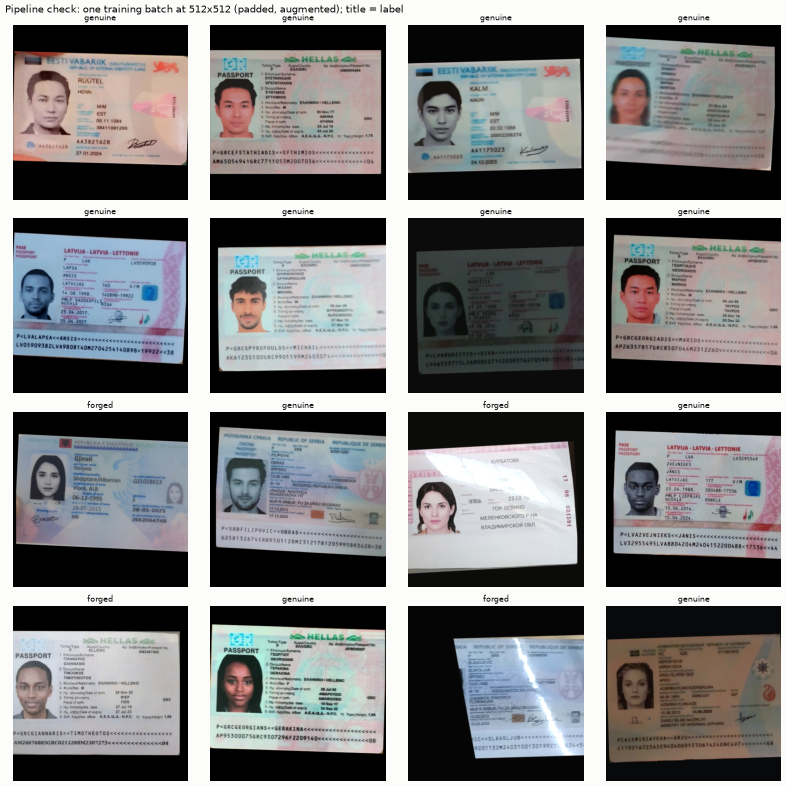

batch (16, 512, 512, 3), float32, pixel range 0-255, labels [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0]


In [3]:
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(4, 4, figsize=(16, 16), dpi=50, facecolor=SURFACE)
for ax, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    ax.imshow(image.astype("uint8"))
    ax.set_title("forged" if label == 1 else "genuine", fontsize=12, color=INK)
    ax.axis("off")
fig.suptitle(f"Pipeline check: one training batch at {IMAGE_SIZE}x{IMAGE_SIZE} (padded, augmented); title = label",
             x=0.01, ha="left", color=INK, fontsize=15)
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_pipeline_check.png", dpi=70, facecolor=SURFACE)
plt.show()
print(f"batch {tuple(images.shape)}, {images.dtype.name}, pixel range {images.numpy().min():.0f}-{images.numpy().max():.0f}, "
      f"labels {labels.numpy().tolist()}")

<!-- id: pipeline -->
**Pipeline check.** This is one augmented training batch, exactly as the models receive it: shape
(16, 512, 512, 3), float32, raw pixel values 0–255. Both models rescale the pixels themselves. The black areas are
the `resize_with_pad` padding plus the black fill left by the small random rotations and shifts. Text is never
mirrored. Something already shows here: the forged video frames (rows 3 and 4, third column) look different from
the genuine ones, with strong glare, a different background and different framing. The source breakdown below
shows why this matters.

In [4]:
b1 = models.build_small_cnn(IMAGE_SIZE)
models.compile_forgery_model(b1, B1["learning_rate"], CLIPNORM)
print(f"B1 small CNN: {b1.count_params():,} parameters, all trained from scratch\n")
callbacks_b1 = models.training_callbacks(MODEL_DIR / "forgery_b1.keras", REPORT_DIR / "forgery_b1_log.csv",
                                         B1["patience"], MONITOR, "max", B1["reduce_lr_patience"])
# shuffle=False: the tf.data pipeline already reshuffles the training set every epoch.
history_b1 = b1.fit(train_ds, validation_data=val_ds, epochs=B1["max_epochs"], class_weight=class_weight,
                    callbacks=callbacks_b1, shuffle=False, verbose=2)
b1_seconds = callbacks_b1[-1].seconds
print(f"\nB1: {len(b1_seconds)} epochs in {sum(b1_seconds) / 60:.1f} min, {np.mean(b1_seconds) / 60:.1f} min per epoch; "
      f"best val PR-AUC {max(history_b1.history['val_pr_auc']):.4f}")

B1 small CNN: 394,353 parameters, all trained from scratch

Epoch 1/15


620/620 - 307s - 495ms/step - loss: 0.4696 - pr_auc: 0.7563 - roc_auc: 0.8598 - val_loss: 0.7310 - val_pr_auc: 0.8562 - val_roc_auc: 0.9053 - learning_rate: 0.0010


Epoch 2/15


620/620 - 322s - 520ms/step - loss: 0.3770 - pr_auc: 0.8401 - roc_auc: 0.9089 - val_loss: 0.4218 - val_pr_auc: 0.8339 - val_roc_auc: 0.9111 - learning_rate: 0.0010


Epoch 3/15



Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.


... (25 outputs left out)

Epoch 15/15


620/620 - 341s - 549ms/step - loss: 0.1705 - pr_auc: 0.9661 - roc_auc: 0.9798 - val_loss: 0.1737 - val_pr_auc: 0.9656 - val_roc_auc: 0.9795 - learning_rate: 1.2500e-04


Restoring model weights from the end of the best epoch: 15.



B1: 15 epochs in 86.7 min, 5.8 min per epoch; best val PR-AUC 0.9656


<!-- id: b1 -->
**B1 — small CNN trained from scratch.** The network has 394,353 parameters. It ran all 15 epochs; early stopping
never triggered because the best epoch was the last one. `ReduceLROnPlateau` halved the learning rate three times,
from 0.001 down to 0.000125 (after epochs 3, 6 and 12). Best validation PR-AUC: 0.9656 at epoch 15, with ROC-AUC
0.9795. An epoch took 5.8 min on average (86.7 min in total). Epoch 9 took 8.8 min because memory was being freed
by closing other applications at the time. A 0.4-million-parameter network trained from scratch reaching 0.97 is
surprising for edits that are about 11 px tall; the source breakdown below explains it.

In [5]:
b2, backbone = models.build_forgery_detector(IMAGE_SIZE)
models.compile_forgery_model(b2, B2_STAGE1["learning_rate"], CLIPNORM)
print(f"B2 EfficientNetB0: {b2.count_params():,} parameters, "
      f"{int(sum(np.prod(w.shape) for w in b2.trainable_weights)):,} trainable in stage 1 (the head)\n")
callbacks_s1 = models.training_callbacks(MODEL_DIR / "forgery_b2_stage1.keras", REPORT_DIR / "forgery_b2_stage1_log.csv",
                                         B2_STAGE1["patience"], MONITOR, "max")
history_s1 = b2.fit(train_ds, validation_data=val_ds, epochs=B2_STAGE1["max_epochs"], class_weight=class_weight,
                    callbacks=callbacks_s1, shuffle=False, verbose=2)
s1_seconds = callbacks_s1[-1].seconds
print(f"\nB2 stage 1: {len(s1_seconds)} epochs in {sum(s1_seconds) / 60:.1f} min, {np.mean(s1_seconds) / 60:.1f} min per epoch; "
      f"best val PR-AUC {max(history_s1.history['val_pr_auc']):.4f}")

B2 EfficientNetB0: 4,050,852 parameters, 1,281 trainable in stage 1 (the head)

Epoch 1/6


620/620 - 447s - 722ms/step - loss: 0.4309 - pr_auc: 0.8384 - roc_auc: 0.9067 - val_loss: 0.3240 - val_pr_auc: 0.9219 - val_roc_auc: 0.9588


Epoch 2/6


620/620 - 433s - 698ms/step - loss: 0.2989 - pr_auc: 0.9141 - roc_auc: 0.9531 - val_loss: 0.2757 - val_pr_auc: 0.9289 - val_roc_auc: 0.9639


Epoch 3/6


620/620 - 404s - 652ms/step - loss: 0.2640 - pr_auc: 0.9258 - roc_auc: 0.9608 - val_loss: 0.2952 - val_pr_auc: 0.9477 - val_roc_auc: 0.9713


... (4 outputs left out)

Epoch 6/6


620/620 - 428s - 691ms/step - loss: 0.2307 - pr_auc: 0.9396 - roc_auc: 0.9673 - val_loss: 0.2645 - val_pr_auc: 0.9587 - val_roc_auc: 0.9771


Restoring model weights from the end of the best epoch: 6.



B2 stage 1: 6 epochs in 42.3 min, 7.1 min per epoch; best val PR-AUC 0.9587


<!-- id: b2s1 -->
**B2 stage 1 — frozen EfficientNetB0, only the head is trained.** Only 1,281 of 4,050,852 parameters are trained:
the 1,280 weights and the bias of the sigmoid output. Validation PR-AUC rose every epoch, from 0.9219 to 0.9587
(ROC-AUC 0.9771), and stopped at the 6-epoch limit. An epoch took 7.1 min (42.3 min in total). Frozen ImageNet
features describe overall appearance: lighting, sharpness, colour and background. That they score this well
without any fine-tuning is a first hint that the task can be solved without looking at the edited text.

In [6]:
n_unfrozen = models.unfreeze_top_layers(backbone, B2_STAGE2["unfreeze_layers"])
models.compile_forgery_model(b2, B2_STAGE2["learning_rate"], CLIPNORM)  # re-compile after changing trainable
n_bn_trainable = sum(l.trainable for l in backbone.layers if isinstance(l, keras.layers.BatchNormalization))
print(f"unfrozen {n_unfrozen} of the top {B2_STAGE2['unfreeze_layers']} backbone layers; trainable BatchNormalization "
      f"layers: {n_bn_trainable}; trainable parameters now {int(sum(np.prod(w.shape) for w in b2.trainable_weights)):,}\n")
callbacks_s2 = models.training_callbacks(MODEL_DIR / "forgery_b2_stage2.keras", REPORT_DIR / "forgery_b2_stage2_log.csv",
                                         B2_STAGE2["patience"], MONITOR, "max", B2_STAGE2["reduce_lr_patience"])
history_s2 = b2.fit(train_ds, validation_data=val_ds, epochs=B2_STAGE2["max_epochs"], class_weight=class_weight,
                    callbacks=callbacks_s2, shuffle=False, verbose=2)
s2_seconds = callbacks_s2[-1].seconds
print(f"\nB2 stage 2: {len(s2_seconds)} epochs in {sum(s2_seconds) / 60:.1f} min, {np.mean(s2_seconds) / 60:.1f} min per epoch; "
      f"best val PR-AUC {max(history_s2.history['val_pr_auc']):.4f}")

unfrozen 15 of the top 20 backbone layers; trainable BatchNormalization layers: 0; trainable parameters now 1,122,865

Epoch 1/8


620/620 - 474s - 765ms/step - loss: 0.2166 - pr_auc: 0.9442 - roc_auc: 0.9706 - val_loss: 0.2465 - val_pr_auc: 0.9598 - val_roc_auc: 0.9776 - learning_rate: 1.0000e-05


Epoch 2/8


620/620 - 449s - 724ms/step - loss: 0.1947 - pr_auc: 0.9538 - roc_auc: 0.9756 - val_loss: 0.2205 - val_pr_auc: 0.9621 - val_roc_auc: 0.9788 - learning_rate: 1.0000e-05


Epoch 3/8


620/620 - 486s - 784ms/step - loss: 0.1797 - pr_auc: 0.9628 - roc_auc: 0.9789 - val_loss: 0.2053 - val_pr_auc: 0.9683 - val_roc_auc: 0.9819 - learning_rate: 1.0000e-05


... (8 outputs left out)

Epoch 8/8


620/620 - 527s - 849ms/step - loss: 0.1480 - pr_auc: 0.9738 - roc_auc: 0.9846 - val_loss: 0.1904 - val_pr_auc: 0.9761 - val_roc_auc: 0.9859 - learning_rate: 1.0000e-05


Restoring model weights from the end of the best epoch: 8.



B2 stage 2: 8 epochs in 62.0 min, 7.8 min per epoch; best val PR-AUC 0.9761


<!-- id: b2s2 -->
**B2 stage 2 — top layers fine-tuned.** The top 20 backbone layers contain 5 BatchNormalization layers. Those stay
frozen (0 trainable BatchNormalization layers), and the other 15 layers are trained: 1,122,865 parameters at
learning rate 0.00001 with gradient clipping. This time training was stable: no NaN, and the learning rate never
had to be reduced, because validation PR-AUC improved every epoch (0.9598 → 0.9761). The best result was at
epoch 8, the limit: PR-AUC 0.9761, ROC-AUC 0.9859. An epoch took 7.8 min (62.0 min in total). The Phase 3A fixes
(frozen BatchNormalization, clipping, `TerminateOnNaN`) worked.

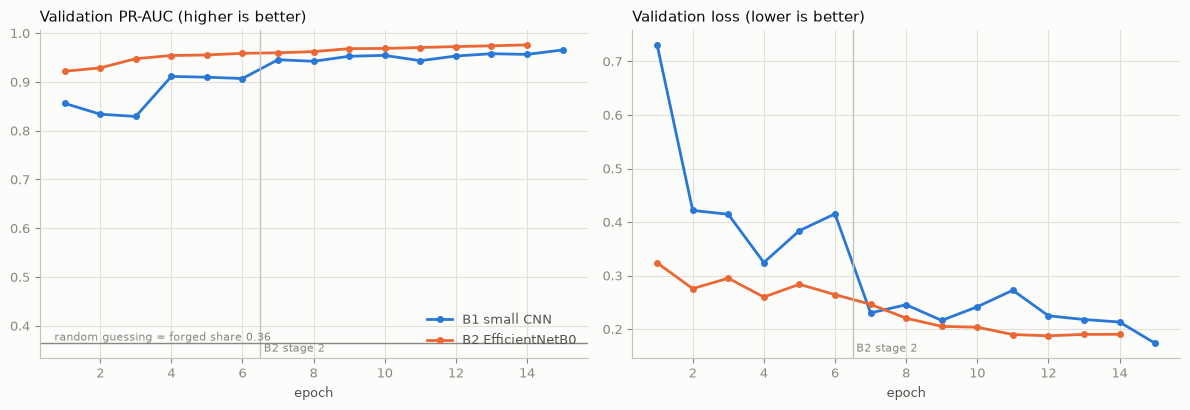

loss  pr_auc  val_loss  val_pr_auc  val_roc_auc
B1         0   0.4696  0.7563    0.7310      0.8562       0.9053
           1   0.3770  0.8401    0.4218      0.8339       0.9111
           2   0.3278  0.8809    0.4146      0.8292       0.9121
           3   0.2600  0.9241    0.3245      0.9113       0.9375
           4   0.2459  0.9316    0.3840      0.9098       0.9356
           5   0.2356  0.9371    0.4153      0.9070       0.9391
           6   0.2131  0.9512    0.2304      0.9456       0.9655
           7   0.2047  0.9528    0.2456      0.9423       0.9608
           8   0.1948  0.9558    0.2163      0.9527       0.9698
           9   0.1894  0.9578    0.2418      0.9545       0.9659
           10  0.1910  0.9582    0.2727      0.9436       0.9559
           11  0.1838  0.9627    0.2250      0.9532       0.9714
           12  0.1716  0.9652    0.2181      0.9579       0.9730
           13  0.1680  0.9671    0.2134      0.9565       0.9699
           14  0.1705  0.9661    0.1737      0.9656       0.9795
B2 stage 1 0   0.4309  0.8384    0.3240      0.9219       0.9588
           1   0.2989  0.9141    0.2757      0.9289       0.9639
           2   0.2640  0.9258    0.2952      0.9477       0.9713
           3   0.2475  0.9342    0.2600      0.9542       0.9745
           4   0.2366  0.9377    0.2839      0.9554       0.9753
           5   0.2307  0.9396    0.2645      0.9587       0.9771
B2 stage 2 0   0.2166  0.9442    0.2465      0.9598       0.9776
           1   0.1947  0.9538    0.2205      0.9621       0.9788
           2   0.1797  0.9628    0.2053      0.9683       0.9819
           3   0.1753  0.9659    0.2037      0.9687       0.9822
           4   0.1679  0.9683    0.1900      0.9706       0.9831
           5   0.1550  0.9721    0.1877      0.9725       0.9841
           6   0.1547  0.9720    0.1902      0.9741       0.9849
           7   0.1480  0.9738    0.1904      0.9761       0.9859

In [7]:
logs = {name: pd.read_csv(REPORT_DIR / f"forgery_{name}_log.csv") for name in ("b1", "b2_stage1", "b2_stage2")}
b2_log = pd.concat([logs["b2_stage1"], logs["b2_stage2"]], ignore_index=True)
forged_share = val["label"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100, facecolor=SURFACE)
for ax, metric, title in [(axes[0], "val_pr_auc", "Validation PR-AUC (higher is better)"),
                          (axes[1], "val_loss", "Validation loss (lower is better)")]:
    ax.plot(np.arange(1, len(logs["b1"]) + 1), logs["b1"][metric], color=BLUE, linewidth=2, marker="o", markersize=4,
            label="B1 small CNN")
    ax.plot(np.arange(1, len(b2_log) + 1), b2_log[metric], color=ORANGE, linewidth=2, marker="o", markersize=4,
            label="B2 EfficientNetB0")
    ax.axvline(len(logs["b2_stage1"]) + 0.5, color=AXIS, linewidth=1)
    ax.text(len(logs["b2_stage1"]) + 0.6, 0.02, "B2 stage 2", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8)
    style(ax, title)
    ax.set_xlabel("epoch", color=INK_2, fontsize=9)
axes[0].axhline(forged_share, color=MUTED, linewidth=1)
axes[0].text(0.6, forged_share, f" random guessing = forged share {forged_share:.2f}", color=MUTED, fontsize=8, va="bottom")
axes[0].legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_training_curves.png", dpi=150, facecolor=SURFACE)
plt.show()
display(pd.concat({"B1": logs["b1"], "B2 stage 1": logs["b2_stage1"], "B2 stage 2": logs["b2_stage2"]})
        [["loss", "pr_auc", "val_loss", "val_pr_auc", "val_roc_auc"]].round(4))

<!-- id: curves -->
**Training curves.** B2 (orange) starts higher and improves smoothly. B1 (blue) is unstable early on: from epoch 2
to epoch 6 its validation loss stays between 0.32 and 0.42 while its training loss falls. It settles after the
learning-rate cuts. Training and validation PR-AUC stay close (B2: 0.974 and 0.976), so there is no sign of
classic overfitting. Neither curve is flat at its last epoch, so more epochs would add a little. The source
breakdown below shows that extra training would mostly sharpen a shortcut, not forgery detection. The grey
vertical line marks where B2 switches from stage 1 to stage 2.

In [8]:
y_val = val["label"].to_numpy()
checkpoints = {"B1": "forgery_b1.keras", "B2 stage 1": "forgery_b2_stage1.keras", "B2 stage 2": "forgery_b2_stage2.keras"}
loaded, scores = {}, {}
for name, file in checkpoints.items():
    if not (MODEL_DIR / file).exists():  # e.g. a stage stopped by TerminateOnNaN before its first checkpoint
        print(f"{name}: no checkpoint saved, skipped")
        continue
    loaded[name] = keras.models.load_model(MODEL_DIR / file)
    scores[name] = loaded[name].predict(val_ds, verbose=0)[:, 0]
ranking = pd.DataFrame({name: evaluation.ranking_scores(y_val, s) for name, s in scores.items()}).T
display(ranking.round(4))

b2_choice = max([n for n in scores if n.startswith("B2")], key=lambda n: ranking.loc[n, "pr_auc"])
final = {"B1": scores["B1"], "B2": scores[b2_choice]}  # the two models compared from here on
best_name = max(final, key=lambda n: ranking.loc["B1" if n == "B1" else b2_choice, "pr_auc"])
best_file = checkpoints["B1" if best_name == "B1" else b2_choice]
print(f"B2 uses its {b2_choice} checkpoint. Best model by validation PR-AUC: {best_name} ({best_file}). "
      f"Random guessing would score {forged_share:.3f}.")

,pr_auc,roc_auc
B1,0.9658,0.9795
B2 stage 1,0.9590,0.9772
B2 stage 2,0.9760,0.9859


B2 uses its B2 stage 2 checkpoint. Best model by validation PR-AUC: B2 (forgery_b2_stage2.keras). Random guessing would score 0.364.


<!-- id: choose -->
**Model choice.** Every saved checkpoint is scored on the full validation set. Validation PR-AUC: B1 0.9658, B2
stage 1 0.9590, B2 stage 2 0.9760. B2 therefore uses its stage-2 checkpoint, and B2 is the better model overall.
These values differ from the training logs in the fourth decimal. Keras estimates AUC from 200 fixed thresholds,
while scikit-learn's average precision uses every individual score. Random guessing would score 0.364, the share of
forged images.

In [9]:
thresholds = {name: {"recall >= 0.90": evaluation.threshold_for_recall(y_val, s, 0.90),
                     "F1-optimal": evaluation.f1_optimal_threshold(y_val, s)} for name, s in final.items()}
threshold_table = pd.DataFrame({(m, rule): v for m, rules in thresholds.items() for rule, v in rules.items()}).T
threshold_table.to_csv(REPORT_DIR / "forgery_thresholds_val.csv")
display(threshold_table.round(4))
confusions = {(m, rule): evaluation.confusion_at(y_val, final[m], t["threshold"])
              for m, rules in thresholds.items() for rule, t in rules.items()}
display(pd.concat(confusions, axis=1))

threshold  precision  recall      f1
B1 recall >= 0.90     0.5672     0.8596  0.9010     NaN
   F1-optimal         0.4666     0.8281  0.9661  0.8918
B2 recall >= 0.90     0.8452     0.8906  0.9010     NaN
   F1-optimal         0.7399     0.8457  0.9779  0.9070

B1                                                      \
           recall >= 0.90                         F1-optimal                    
        predicted genuine predicted forged predicted genuine predicted forged   
genuine              1228              113              1187              154   
forged                 76              692                26              742   

                       B2                                                      
           recall >= 0.90                         F1-optimal                   
        predicted genuine predicted forged predicted genuine predicted forged  
genuine              1256               85              1204              137  
forged                 76              692                17              751

<!-- id: thresholds -->
**Thresholds (validation).** Decision rule: an image is called forged if its score ≥ the threshold.
- *Recall ≥ 0.90* (the highest threshold that still catches 90 % of the forgeries): B2 **0.8452**, precision 0.891,
  recall 0.901. B1: 0.5672, precision 0.860.
- *F1-optimal* (best balance of precision and recall): B2 **0.7399**, precision 0.846, recall 0.978, F1 0.907.
  B1: 0.4666, F1 0.892.
- *Confusion matrix, B2 at the recall-0.90 threshold:* 692 of 768 forgeries caught and 76 missed. 85 of 1,341
  genuine images are wrongly flagged (6.3 %).

At first sight this looks like a strong detector. The breakdown below shows it is not, on the images that matter.

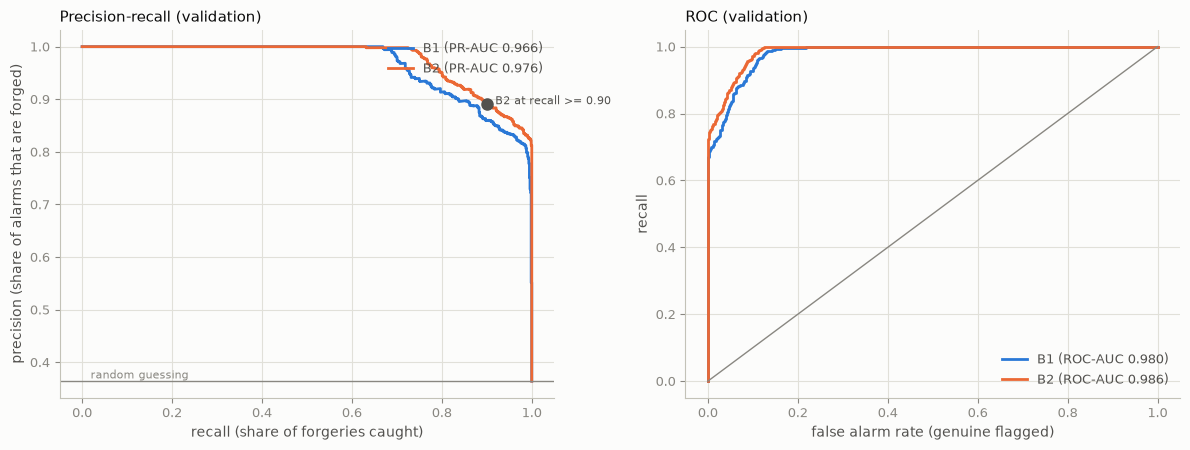

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), dpi=100, facecolor=SURFACE)
for name, color in (("B1", BLUE), ("B2", ORANGE)):
    precision, recall, _ = precision_recall_curve(y_val, final[name])
    axes[0].plot(recall, precision, color=color, linewidth=2, label=f"{name} (PR-AUC {ranking.loc['B1' if name == 'B1' else b2_choice, 'pr_auc']:.3f})")
    fpr, tpr, _ = roc_curve(y_val, final[name])
    axes[1].plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (ROC-AUC {ranking.loc['B1' if name == 'B1' else b2_choice, 'roc_auc']:.3f})")
best_t = thresholds[best_name]["recall >= 0.90"]
axes[0].plot(best_t["recall"], best_t["precision"], "o", color=INK_2, markersize=8)
axes[0].annotate(f"  {best_name} at recall >= 0.90", (best_t["recall"], best_t["precision"]), color=INK_2, fontsize=8)
axes[0].axhline(forged_share, color=MUTED, linewidth=1)
axes[0].text(0.01, forged_share, " random guessing", color=MUTED, fontsize=8, va="bottom")
axes[1].plot([0, 1], [0, 1], color=MUTED, linewidth=1)
style(axes[0], "Precision-recall (validation)")
style(axes[1], "ROC (validation)")
axes[0].set(xlabel="recall (share of forgeries caught)", ylabel="precision (share of alarms that are forged)")
axes[1].set(xlabel="false alarm rate (genuine flagged)", ylabel="recall")
for ax in axes:
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)
    ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower right" if ax is axes[1] else "upper right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "forgery_pr_roc_val.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: curves_pr -->
**Precision–recall and ROC curves.** Both models keep perfect precision (1.0) up to roughly two thirds recall: a large
block of forgeries scores higher than every genuine image. After that, precision drops. This two-part shape is
typical of a mix of two subsets, one easy to separate and one hard. The source breakdown below shows exactly that.

In [11]:
frame = val.assign(score_B1=final["B1"], score_B2=final["B2"])
breakdowns = {}
for by in ("source", "ctype", "doc_type", "altered_field"):
    parts = {}
    for name in final:
        table = evaluation.breakdown(frame.assign(score=frame[f"score_{name}"]), by,
                                     thresholds[name]["recall >= 0.90"]["threshold"])
        if by in ("ctype", "altered_field"):  # forged images only: recall is the only meaningful number
            table = table[["forged", "recall"]]
        parts[name] = table
    breakdowns[by] = pd.concat(parts, axis=1)
    breakdowns[by].to_csv(REPORT_DIR / f"forgery_breakdown_{by}_val.csv")
print("All breakdowns at each model's recall >= 0.90 threshold (validation).")
for by in ("source", "ctype", "doc_type"):
    display(breakdowns[by].round(3))
fields = breakdowns["altered_field"]
display(fields.sort_values((best_name, "forged"), ascending=False).head(15).round(3))

All breakdowns at each model's recall >= 0.90 threshold (validation).


B1                                                 B2         \
          images forged recall false_alarm precision pr_auc  images forged   
source                                                                       
clip      1780.0  589.0  0.944       0.001     0.998  0.997  1780.0  589.0   
template   329.0  179.0  0.760       0.747     0.548  0.571   329.0  179.0   

                                              
         recall false_alarm precision pr_auc  
source                                        
clip      0.990       0.008     0.985  0.999  
template  0.609       0.507     0.589  0.591

B1            B2       
                    forged recall forged recall
ctype                                          
Crop_and_Replace      82.0  0.976   82.0  0.841
Inpaint_and_Rewrite  686.0  0.892  686.0  0.908

B1                                                B2  \
                     images forged recall false_alarm precision pr_auc images   
doc_type                                                                        
alb_id                178.0   54.0  0.796       0.113     0.754  0.909  178.0   
aze_passport          184.0   69.0  0.971       0.122     0.827  0.986  184.0   
esp_id                190.0   64.0  0.828       0.016     0.964  0.982  190.0   
est_id                177.0   53.0  0.774       0.032     0.911  0.961  177.0   
fin_id                193.0   58.0  0.690       0.000     1.000  0.965  193.0   
grc_passport          270.0  126.0  1.000       0.111     0.887  0.986  270.0   
lva_passport          210.0   60.0  1.000       0.113     0.779  0.956  210.0   
rus_internalpassport  256.0  121.0  1.000       0.111     0.890  0.989  256.0   
srb_passport          233.0   80.0  1.000       0.111     0.825  0.971  233.0   
svk_id                218.0   83.0  0.735       0.104     0.813  0.911  218.0   

                                                                 
                     forged recall false_alarm precision pr_auc  
doc_type                                                         
alb_id                 54.0  0.870       0.073     0.839  0.956  
aze_passport           69.0  1.000       0.148     0.802  0.987  
esp_id                 64.0  0.969       0.087     0.849  0.981  
est_id                 53.0  0.849       0.056     0.865  0.956  
fin_id                 58.0  0.759       0.007     0.978  0.984  
grc_passport          126.0  1.000       0.111     0.887  0.987  
lva_passport           60.0  0.733       0.020     0.936  0.968  
rus_internalpassport  121.0  0.975       0.104     0.894  0.985  
srb_passport           80.0  0.775       0.013     0.969  0.976  
svk_id                 83.0  0.904       0.037     0.938  0.982

B1            B2       
                forged recall forged recall
altered_field                              
gender           100.0  0.920  100.0  0.920
issue_date        88.0  0.727   88.0  0.943
surname           83.0  0.916   83.0  0.916
patronymic        67.0  1.000   67.0  1.000
expiry_date       55.0  0.909   55.0  0.909
number            50.0  0.780   50.0  0.900
height            49.0  1.000   49.0  0.898
mrz_line0         46.0  0.957   46.0  0.978
type              44.0  1.000   44.0  1.000
name              36.0  0.861   36.0  0.806
birth_place       34.0  1.000   34.0  0.853
nationality       28.0  0.929   28.0  0.857
issue_place       24.0  1.000   24.0  0.958
residence_line0   22.0  1.000   22.0  0.909
birth_date         8.0  0.500    8.0  0.375

<!-- id: breakdown -->
**Breakdowns at each model's recall-0.90 threshold — the key result of this notebook.**

| subset (validation) | images (forged) | B2 PR-AUC | B2 recall | B2 false alarms | B1 PR-AUC |
|---|---|---|---|---|---|
| video clip frames | 1,780 (589) | 0.999 | 0.990 | 0.8 % | 0.997 |
| templates (clean scans) | 329 (179) | **0.591** | 0.609 | **50.7 %** | 0.571 |

- **On clip frames both models are almost perfect; on templates they are close to random guessing.** On
  templates, random scores would give PR-AUC = forged share = 179 / 329 = 0.544. Templates account for 76 of B2's
  85 false alarms and 70 of its 76 missed forgeries.
- **Why.** Within the clips, the label is fully tied to how the video was produced. Every genuine clip frame comes
  from the original MIDV-2020 videos (JPEG files). The forged clip frames come from a separate set of recordings of
  the forged documents, with different glare, background and framing (see the pipeline check). Even the file
  format differs (next cell). The models learned to recognise the recording, not the edit. If they had learned the edit, they
  would do better on templates than on clips, because a scan shows the edited text more sharply than a video
  frame. They do the opposite.
- **So the overall 0.976 measures the difference in recording, not forgery detection.** The doc-type, ctype and
  field tables mix the two subsets and carry the same bias. Examples: B2 recall is 0.841 on Crop_and_Replace and
  0.908 on Inpaint_and_Rewrite, and 3 of 8 birth_date edits are caught. These numbers mostly reflect how many of
  each group's forgeries are clips.

In [8]:
# Why do clip frames separate perfectly? Look at the files themselves (train + val only; test is not used).
from ekyc.data import estimate_jpeg_quality, image_format

files = pd.concat([train, val])[["image_path", "source", "label"]].copy()
files["class"] = files["label"].map({0: "genuine", 1: "forged"})
files["format"] = [image_format(ROOT / p) for p in files["image_path"]]  # from the content, not the .jpg name
files["jpeg quality"] = [estimate_jpeg_quality(ROOT / p) for p in files["image_path"]]  # None for PNG files
display(pd.crosstab([files["source"], files["class"]], files["format"]))
display(files.dropna(subset=["jpeg quality"]).groupby(["source", "class"])["jpeg quality"]
        .describe()[["count", "min", "50%", "max"]].astype(int))

format            JPEG   PNG
source   class              
clip     forged      0  3365
         genuine  6770     0
template forged   1032     0
         genuine   852     0

count  min  50%  max
source   class                        
clip     genuine   6770   95   95   95
template forged    1032   75   75   75
         genuine    852   92   92   92

<!-- id: source_check -->
**File check: the label can be read from the file itself.** The table reads each file's real format from its
content, not its `.jpg` name, and estimates the JPEG quality from the quantisation table stored in the file
(`ekyc.data.estimate_jpeg_quality`, which recovers the exact quality in tests). Train and validation images only.
- **Clips:** all 3,365 forged frames are PNG files with a `.jpg` name. All 6,770 genuine frames are real JPEGs
  saved at quality 95. Format, compression and recording all change together with the label, so clip frames
  cannot be used to train or evaluate a forgery detector.
- **Templates:** all 852 genuine templates are JPEG quality 92 and all 1,032 forged templates are JPEG quality
  75. The 512 px cache re-saves every image at quality 92, and shrinking the pages to 512 px blurs most of
this difference away,
  which fits the near-chance template scores. A higher-resolution model would see the coarser compression of the
  forged files and could learn that instead of the edit. The v2 detector (notebook 03b) therefore re-saves both
  classes the same way.

*Note:* this cell, the saved-model cell and the Grad-CAM grid were re-run after the main run, without any
retraining. The variables they need were rebuilt in a fresh kernel from the saved checkpoints, which is why their
execution numbers are out of sequence.

In [6]:
# Saved under a "v1_confounded" name: the breakdown above shows this model learned a shortcut, so it
# must never be picked up as the pipeline's forgery detector (models/forgery_detector.keras is v2).
V1_NAME = "forgery_detector_v1_confounded"
shutil.copy(MODEL_DIR / best_file, MODEL_DIR / f"{V1_NAME}.keras")
best_ranking = ranking.loc["B1" if best_name == "B1" else b2_choice]
detector_info = {
    "warning": "v1: learned the clip recording style, not the edits (near chance on templates). "
               "Do not use in the pipeline.",
    "model": f"{best_name} ({best_file})",
    "input_size": IMAGE_SIZE,
    "output": "sigmoid probability that the image is forged",
    "decision_rule": "forged if score >= threshold",
    "thresholds": {"recall_0.90": {k: round(v, 4) for k, v in thresholds[best_name]["recall >= 0.90"].items()},
                   "f1_optimal": {k: round(v, 4) for k, v in thresholds[best_name]["F1-optimal"].items()}},
    "preprocessing": "512 px RGB cache image (never the raw file: CMYK originals) -> tf.image.resize_with_pad(512, 512) "
                     "-> float32 pixels 0-255; the model rescales internally; do not divide by 255",
    "notes": "skip frames flagged is_empty; thresholds were chosen on validation and must be re-checked on test",
    "val_pr_auc": round(float(best_ranking["pr_auc"]), 4),
    "val_roc_auc": round(float(best_ranking["roc_auc"]), 4),
}
(MODEL_DIR / f"{V1_NAME}.json").write_text(json.dumps(detector_info, indent=2))
print(json.dumps(detector_info, indent=2))

{
  "warning": "v1: learned the clip recording style, not the edits (near chance on templates). Do not use in the pipeline.",
  "model": "B2 (forgery_b2_stage2.keras)",
  "input_size": 512,
  "output": "sigmoid probability that the image is forged",
  "decision_rule": "forged if score >= threshold",
  "thresholds": {
    "recall_0.90": {
      "threshold": 0.8452,
      "precision": 0.8906,
      "recall": 0.901
    },
    "f1_optimal": {
      "threshold": 0.7399,
      "precision": 0.8457,
      "recall": 0.9779,
      "f1": 0.907
    }
  },
  "preprocessing": "512 px RGB cache image (never the raw file: CMYK originals) -> tf.image.resize_with_pad(512, 512) -> float32 pixels 0-255; the model rescales internally; do not divide by 255",
  "notes": "skip frames flagged is_empty; thresholds were chosen on validation and must be re-checked on test",
  "val_pr_auc": 0.976,
  "val_roc_auc": 0.9859
}


<!-- id: saved -->
**Saved model.** `models/forgery_detector_v1_confounded.keras` is a copy of the B2 stage-2 checkpoint.
`models/forgery_detector_v1_confounded.json` stores the input size, both thresholds and the preprocessing, so a later service can
reproduce the exact input. **Because of the breakdown above, this model must not be used as the forgery worker in
its current form:** on clean scans it is hardly better than chance. It is kept, under a name that says so and with a warning in its JSON, as the record of this experiment.
The name `forgery_detector.keras` is left free for the v2 tile model (notebook 03b).

In [13]:
gt = pd.read_csv(config.FIELDS_GT_CSV)
box_of = gt.set_index(["doc_id", "field_name"])[["x", "y", "w", "h"]]
b2_model = loaded[b2_choice]
feature_model, output_layer = gradcam.gradcam_parts(b2_model)
b2_threshold = thresholds["B2"]["recall >= 0.90"]["threshold"]


def pointing_game(rows):
    """Hit / chance level for every forged image in `rows` (heat maps are computed batch by batch)."""
    results = []
    paths = [ROOT / p for p in rows["cache_path"]]
    batches = tfdata.make_dataset_from_paths(paths, IMAGE_SIZE, BATCH_SIZE)
    row_iter = rows.itertuples()
    for batch in batches:
        for heat in gradcam.gradcam(feature_model, output_layer, batch):
            row = next(row_iter)
            with Image.open(ROOT / row.cache_path) as image:
                cache_size = image.size
            box = gradcam.box_to_input(box_of.loc[(row.doc_id, row.altered_field)],
                                       (row.orig_width, row.orig_height), cache_size, IMAGE_SIZE)
            scale = tfdata.pad_geometry(*cache_size, IMAGE_SIZE)[0]
            document_area = cache_size[0] * scale * cache_size[1] * scale
            results.append({"hit": gradcam.point_in_box(gradcam.peak_location(heat), box),
                            "chance": box[2] * box[3] / document_area})
    return pd.DataFrame(results, index=rows.index)


forged_val = val.assign(score=final["B2"])[val["label"] == 1]
pointing = {}
for source in ("template", "clip"):  # clip boxes line up after dewarping (checked visually before this run)
    rows = forged_val[forged_val["source"] == source]
    result = pointing_game(rows).join(rows[["score"]])
    detected = result["score"] >= b2_threshold
    pointing[source] = {"forged images": len(result), "pointing score": result["hit"].mean(),
                        "chance level": result["chance"].mean(),
                        "pointing score, detected forgeries only": result.loc[detected, "hit"].mean(),
                        "detected forgeries": int(detected.sum())}
pointing_table = pd.DataFrame(pointing).T
pointing_table.to_csv(REPORT_DIR / "forgery_gradcam_pointing_val.csv")
display(pointing_table.round(3))

,forged images,pointing score,chance level,"pointing score, detected forgeries only",detected forgeries
template,179.0,0.0,0.006,0.0,109.0
clip,589.0,0.0,0.005,0.0,583.0


<!-- id: pointing -->
**Grad-CAM pointing game (B2).** The hottest point of the heat map never lies inside the altered field: 0 of 179
forged templates and 0 of 589 forged clip frames. It is also 0 among the 109 and 583 that B2 actually flags. A point
placed at random would land inside the box 0.6 % and 0.5 % of the time, the share of the document the box covers.
That is about 1 and 3 hits expected by chance, so 0 is in line with chance. The heat maps agree with the breakdown:
B2's decision is not based on the edited text.

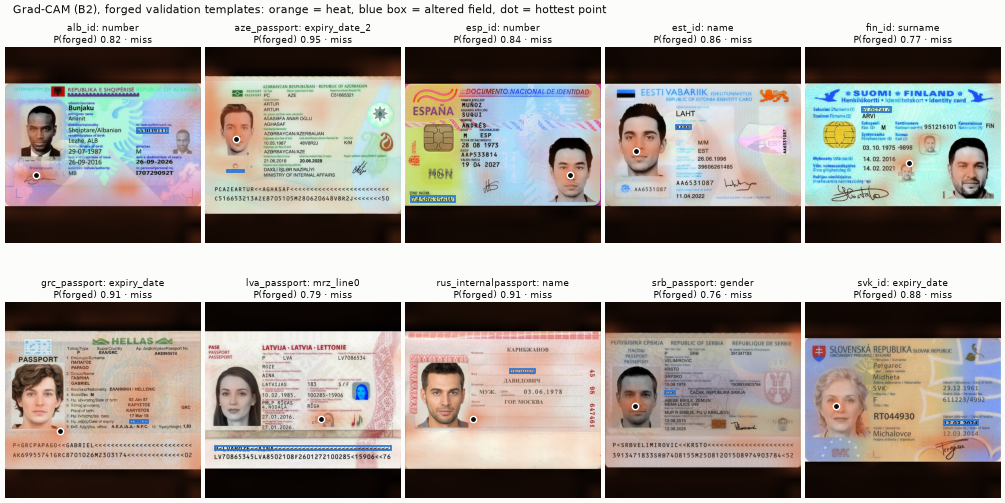

In [9]:
examples = (forged_val[forged_val["source"] == "template"].sort_values("fake_name")
            .groupby("doc_type").head(1).sort_values("doc_type"))
heat_cmap = LinearSegmentedColormap.from_list("heat", [(0.92, 0.41, 0.20, 0.0), (0.92, 0.41, 0.20, 0.75)])
batch = tf.stack([tfdata.load_image(str(ROOT / p), IMAGE_SIZE) for p in examples["cache_path"]])
heats = gradcam.gradcam(feature_model, output_layer, batch)

# constrained layout reserves room for every title, so the bottom-row titles no longer hide
# behind the top-row images (they did with tight_layout in the first run)
fig, axes = plt.subplots(2, 5, figsize=(20, 10.5), dpi=50, facecolor=SURFACE, layout="constrained")
for ax in axes.flat:
    ax.axis("off")
for ax, row, image, heat in zip(axes.flat, examples.itertuples(), batch.numpy(), heats):
    with Image.open(ROOT / row.cache_path) as cached:
        cache_size = cached.size
    x, y, w, h = gradcam.box_to_input(box_of.loc[(row.doc_id, row.altered_field)],
                                      (row.orig_width, row.orig_height), cache_size, IMAGE_SIZE)
    peak = gradcam.peak_location(heat)
    ax.imshow(image.astype("uint8"))
    ax.imshow(heat, cmap=heat_cmap, vmin=0, vmax=1)
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=BLUE, linewidth=2.5))
    ax.plot(*peak, "o", markersize=9, markerfacecolor=INK, markeredgecolor="white", markeredgewidth=2)
    hit = "hit" if gradcam.point_in_box(peak, (x, y, w, h)) else "miss"
    ax.set_title(f"{row.doc_type}: {row.altered_field}\nP(forged) {row.score:.2f} · {hit}", fontsize=13, color=INK)
    ax.axis("off")
fig.suptitle("Grad-CAM (B2), forged validation templates: orange = heat, blue box = altered field, dot = hottest point",
             x=0.01, ha="left", color=INK, fontsize=16)
fig.savefig(REPORT_DIR / "forgery_gradcam_val.png", dpi=70, facecolor=SURFACE)
plt.show()

<!-- id: gradcam_grid -->
**Grad-CAM examples.** The grid shows one forged validation template per document type, with the document type
and the altered field in each title. The blue boxes sit exactly on the
edited fields (for example the number on alb_id and esp_id, and the first MRZ line on lva_passport), which confirms
that the boxes are mapped correctly from the original image to the cache and then to the padded input. The black
dots, the hottest points, are mostly on or next to the portrait photo and never on the edit. The scores are high
(0.76–0.95), but B2 flags 51 % of *genuine* templates as well. A high score here means "this is a template", not
"this field was edited".

In [15]:
seconds = {"B1": b1_seconds, "B2 stage 1": s1_seconds, "B2 stage 2": s2_seconds}
metrics = {
    "split": "validation (test not used)",
    "images": {"train": len(train), "val": len(val), "empty_frames_excluded": len(excluded)},
    "ranking": ranking.round(4).to_dict(orient="index"),
    "b2_checkpoint": b2_choice,
    "best_model": best_name,
    "thresholds": {m: {rule: {k: round(v, 4) for k, v in t.items()} for rule, t in rules.items()}
                   for m, rules in thresholds.items()},
    "gradcam_pointing": {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in pointing.items()},
    "epochs": {k: len(v) for k, v in seconds.items()},
    "mean_epoch_minutes": {k: round(float(np.mean(v)) / 60, 2) for k, v in seconds.items()},
    "peak_memory_gb": round(peak_memory_gb(), 2),
}
(REPORT_DIR / "forgery_metrics_val.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps({k: metrics[k] for k in ("epochs", "mean_epoch_minutes", "peak_memory_gb")}, indent=2))
print(f"swap in use now: {swap_used_gb():.1f} GB | notebook run time: {(time.perf_counter() - notebook_start) / 60:.1f} min")
for path in sorted(REPORT_DIR.glob("forgery_*")):
    print(f"  reports/phase3/{path.name}")

{
  "epochs": {
    "B1": 15,
    "B2 stage 1": 6,
    "B2 stage 2": 8
  },
  "mean_epoch_minutes": {
    "B1": 5.78,
    "B2 stage 1": 7.06,
    "B2 stage 2": 7.75
  },
  "peak_memory_gb": 15.0
}


swap in use now: 16.6 GB | notebook run time: 194.6 min
  reports/phase3/forgery_b1_log.csv
  reports/phase3/forgery_b2_stage1_log.csv
  reports/phase3/forgery_b2_stage2_log.csv
  reports/phase3/forgery_breakdown_altered_field_val.csv
  reports/phase3/forgery_breakdown_ctype_val.csv
  reports/phase3/forgery_breakdown_doc_type_val.csv
  reports/phase3/forgery_breakdown_source_val.csv
  reports/phase3/forgery_gradcam_pointing_val.csv
  reports/phase3/forgery_gradcam_val.png
  reports/phase3/forgery_metrics_val.json
  reports/phase3/forgery_pipeline_check.png
  reports/phase3/forgery_pr_roc_val.png
  reports/phase3/forgery_thresholds_val.csv
  reports/phase3/forgery_training_curves.png


<!-- id: summary -->
**Summary (validation only; the test set was not used).**
- **Data:** 9,910 training and 2,109 validation images; 62 empty frames excluded; class weights genuine 0.79,
  forged 1.37.
- **B1, small CNN:** validation PR-AUC 0.966, ROC-AUC 0.980. **B2, EfficientNetB0 stage 2:** PR-AUC 0.976,
  ROC-AUC 0.986. B2 is chosen and saved as `models/forgery_detector_v1_confounded.keras`.
- **B2 thresholds:** 0.845 for recall ≥ 0.90 (precision 0.891); F1-optimal 0.740 (F1 0.907).
- **But these scores come from the video frames**, where genuine and forged frames were recorded separately and the
  models recognise the recording. On templates, the only clean test of the edit itself, B2 reaches PR-AUC 0.591,
  against 0.544 for random guessing. Grad-CAM never points at the altered field (0 of 768 forged images).
- **Cost:** the whole notebook took 194.6 min. Average epoch: B1 5.8 min; B2 7.1 min (stage 1) and 7.8 min
  (stage 2), all at 512 px. Peak memory of the notebook process: 15.0 GB.
- **Next step (to be decided):** remove the recording shortcut from training and evaluation, and give the model
  enough resolution to see edits about 11 px tall (field crops or tiles instead of the whole page). The file check
  shows that forged templates are also stored at a lower JPEG quality than genuine ones (75 against 92). Any higher-resolution design must equalise the
  compression first, or the model will learn the compression instead of the edit.